In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import math

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


In [240]:
df = pd.read_csv("data_reg.csv")
print(df.head())

# If Date is in dd-mm-YYYY format, parse it like this:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Make sure rows are in time order before using lag/shift
df = df.sort_values("Date").reset_index(drop=True)

         Date   Bund    BTP   FOAT  Bonos  DFR  ON-GcPooling  ON-ExtGcPooling  \
0  02-01-2018  0.467  2.095  0.823  1.614 -0.4        -0.439           -0.423   
1  03-01-2018  0.442  2.067  0.797  1.598 -0.4        -0.436           -0.418   
2  04-01-2018  0.434  2.014  0.786  1.543 -0.4        -0.443           -0.414   
3  05-01-2018  0.439  2.006  0.797  1.522 -0.4        -0.445           -0.402   
4  08-01-2018  0.431  1.984  0.788  1.482 -0.4        -0.449           -0.421   

   TN-GcPooling  TN-ExtGcPooling  ...  DeferredRate  ON-GcPoolingVol  \
0        -0.447           -0.450  ...        -0.431             1770   
1        -0.446           -0.440  ...        -0.430             1534   
2        -0.446           -0.435  ...        -0.432             1909   
3        -0.440           -0.388  ...        -0.414             2179   
4        -0.452           -0.411  ...        -0.432             2050   

   ON-ExtGcPoolingVol  TN-GcPoolingVol  TN-ExtGcPoolingVol  SN-GcPoolingVol  \
0

In [241]:
df["ECB_deferred_rate_new"] = (
    df["ON-GcPooling"] * df["ON-GcPoolingVol"]
    + df["TN-GcPooling"].shift(1) * df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPooling"].shift(2) * df["SN-GcPoolingVol"].shift(2)
) / (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["ECB_deferred_vol_new"] = (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["EXT_deferred_rate_new"] = (
    df["ON-ExtGcPooling"] * df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPooling"].shift(1) * df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPooling"].shift(2) * df["SN-ExtGcPoolingVol"].shift(2)
) / (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

df["EXT_deferred_vol_new"] = (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

# Spread
df["DeferredRateSpread"] = df["EXT_deferred_rate_new"] - df["ECB_deferred_rate_new"]

# BTP-Bund spread (this part you intended as subtraction)
df["BTP_Bund_Spread"] = df["BTP"] - df["Bund"]

df["ExcessLiquidityLn"] = np.log(df["ExcessLiquidity"])

#Volume Spread
df["Volume_Spread"] = df["ECB_deferred_vol_new"] - df["EXT_deferred_vol_new"]
df["Liquidity_ratio"] = np.log(df["ECB_deferred_vol_new"]/ df["EXT_deferred_vol_new"])

df.head()

,Date,Bund,BTP,FOAT,Bonos,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,...,CISS,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
0,2018-01-02,0.467,2.095,0.823,1.614,-0.4,-0.439,-0.423,-0.447,-0.450,...,0.0225,NaN,NaN,NaN,NaN,NaN,1.628,14.397679,NaN,NaN
1,2018-01-03,0.442,2.067,0.797,1.598,-0.4,-0.436,-0.418,-0.446,-0.440,...,0.0217,NaN,NaN,NaN,NaN,NaN,1.625,14.416495,NaN,NaN
2,2018-01-04,0.434,2.014,0.786,1.543,-0.4,-0.443,-0.414,-0.446,-0.435,...,0.0295,-0.443661,2449.0,-0.420993,3030.0,0.022668,1.580,14.425921,-581.0,-0.212883
3,2018-01-05,0.439,2.006,0.797,1.522,-0.4,-0.445,-0.402,-0.440,-0.388,...,0.0251,-0.445941,3029.0,-0.403210,4228.0,0.042731,1.567,14.424278,-1199.0,-0.333497
4,2018-01-08,0.431,1.984,0.788,1.482,-0.4,-0.449,-0.421,-0.452,-0.411,...,0.0246,-0.448701,2810.0,-0.411740,4900.0,0.036961,1.553,14.429584,-2090.0,-0.556051


In [242]:
#Conver to basis points
rate_cols = [
    "Bund", "BTP", "FOAT", "Bonos",
    "ON-GcPooling", "ON-ExtGcPooling",
    "TN-GcPooling", "TN-ExtGcPooling",
    "SN-GcPooling", "SN-ExtGcPooling",
    "DeferredRate",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new",
    "DeferredRateSpread", "BTP_Bund_Spread","DFR"
]

df[rate_cols] = df[rate_cols] * 100

In [243]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.sort_values("Date").copy()
df=df.dropna()
df.columns
df.head()

,Date,Bund,BTP,FOAT,Bonos,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,...,CISS,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
2,2018-01-04,43.4,201.4,78.6,154.3,-40.0,-44.3,-41.4,-44.6,-43.5,...,0.0295,-44.366149,2449.0,-42.099340,3030.0,2.266810,158.0,14.425921,-581.0,-0.212883
3,2018-01-05,43.9,200.6,79.7,152.2,-40.0,-44.5,-40.2,-44.0,-38.8,...,0.0251,-44.594090,3029.0,-40.320979,4228.0,4.273111,156.7,14.424278,-1199.0,-0.333497
4,2018-01-08,43.1,198.4,78.8,148.2,-40.0,-44.9,-42.1,-45.2,-41.1,...,0.0246,-44.870107,2810.0,-41.173980,4900.0,3.696127,155.3,14.429584,-2090.0,-0.556051
5,2018-01-09,46.6,203.5,81.8,151.5,-40.0,-45.3,-41.3,-45.7,-41.3,...,0.0239,-45.231011,2957.0,-41.268262,3781.0,3.962749,156.9,14.436468,-824.0,-0.245813
6,2018-01-10,54.3,203.8,81.3,155.1,-40.0,-44.9,-40.4,-44.7,-40.1,...,0.0281,-45.088442,7164.0,-40.534013,5104.0,4.554430,149.5,14.438991,2060.0,0.339044


# Plots

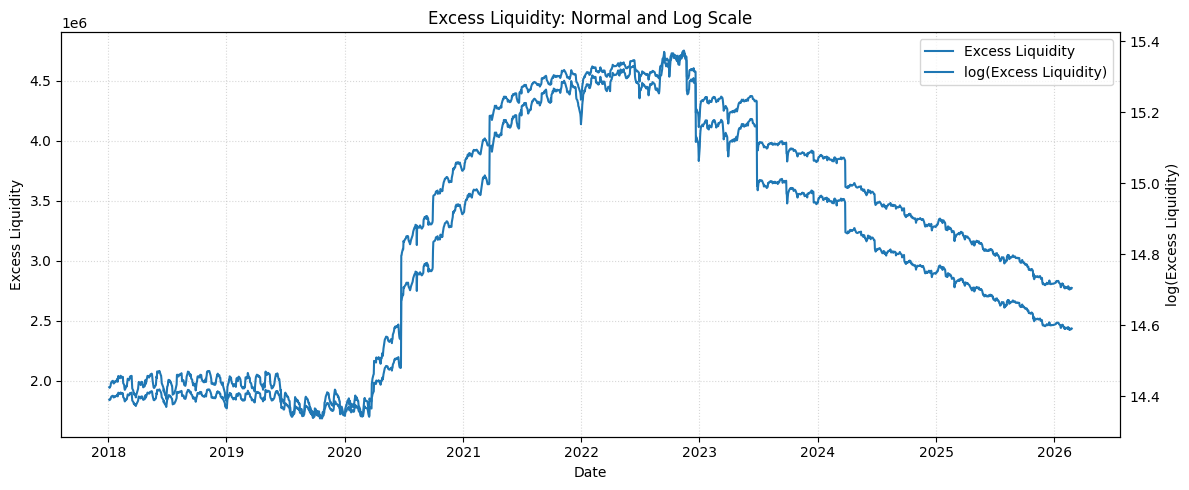

In [112]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["ExcessLiquidity"], label="Excess Liquidity")
ax1.set_xlabel("Date")
ax1.set_ylabel("Excess Liquidity")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidityLn"], label="log(Excess Liquidity)")
ax2.set_ylabel("log(Excess Liquidity)")

ax1.set_title("Excess Liquidity: Normal and Log Scale")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


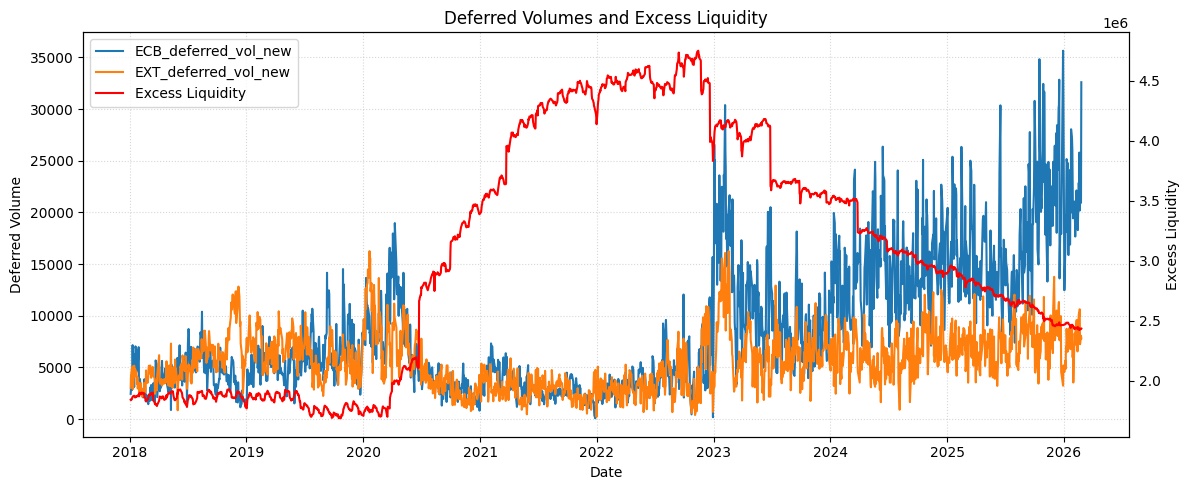

In [113]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["ECB_deferred_vol_new"], label="ECB_deferred_vol_new")
ax1.plot(df["Date"], df["EXT_deferred_vol_new"], label="EXT_deferred_vol_new")
ax1.set_xlabel("Date")
ax1.set_ylabel("Deferred Volume")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidity"], label="Excess Liquidity", color="red")
ax2.set_ylabel("Excess Liquidity")

ax1.set_title("Deferred Volumes and Excess Liquidity")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


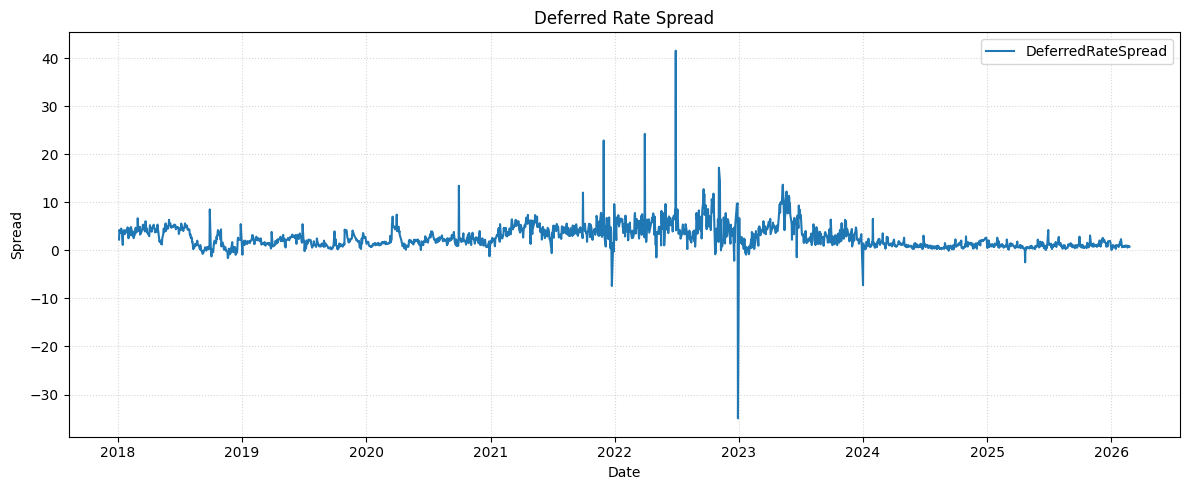

In [63]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["DeferredRateSpread"], label="DeferredRateSpread")
plt.title("Deferred Rate Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

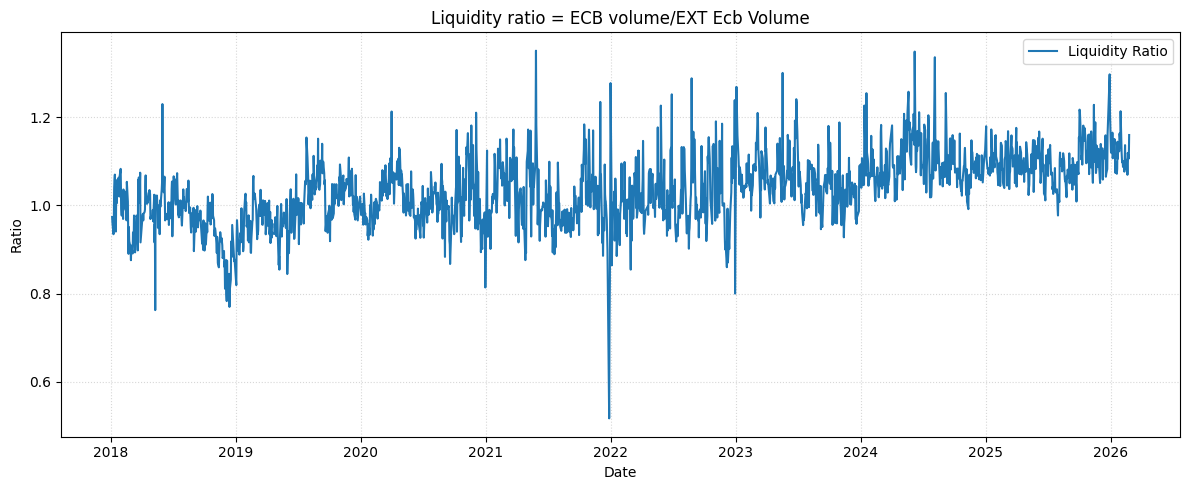

In [64]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Liquidity_ratio"], label="Liquidity Ratio")
plt.title("Liquidity ratio = ECB volume/EXT Ecb Volume")
plt.xlabel("Date")
plt.ylabel("Ratio")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

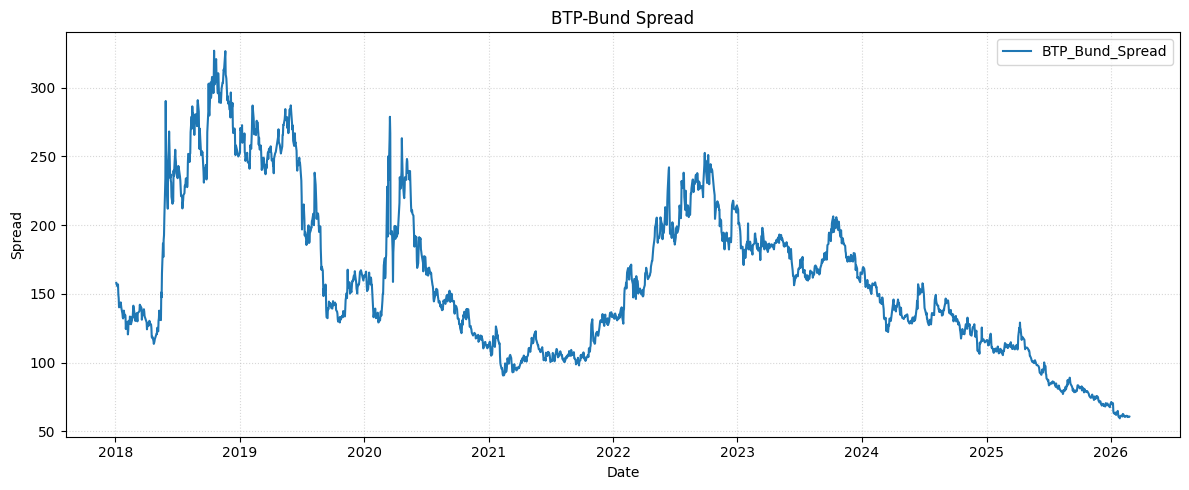

In [65]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["BTP_Bund_Spread"], label="BTP_Bund_Spread")
plt.title("BTP-Bund Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

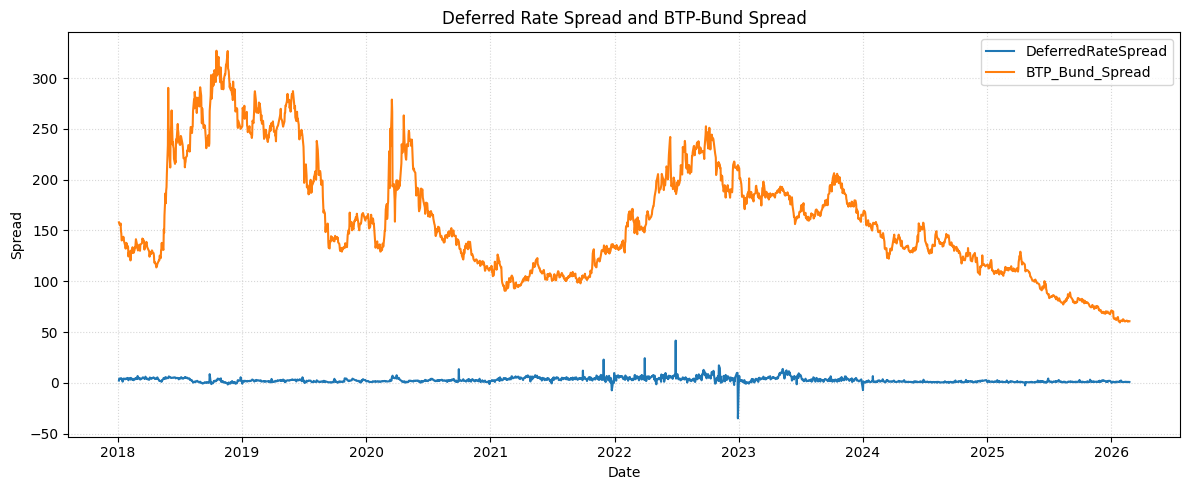

In [66]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["DeferredRateSpread"], label="DeferredRateSpread")
plt.plot(df["Date"], df["BTP_Bund_Spread"], label="BTP_Bund_Spread")
plt.title("Deferred Rate Spread and BTP-Bund Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

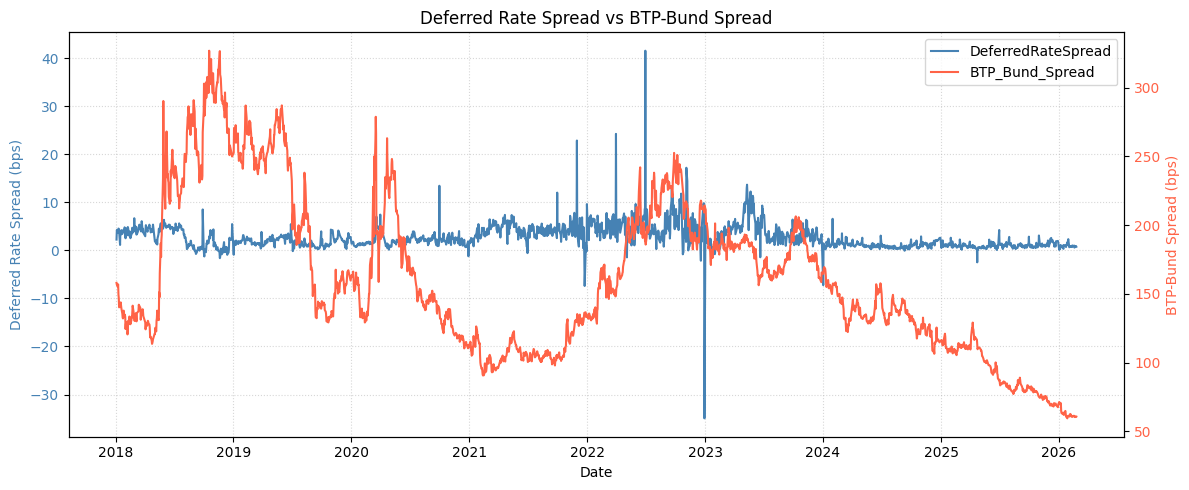

In [67]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary axis (left)
ax1.plot(df["Date"], df["DeferredRateSpread"],
         label="DeferredRateSpread", color="steelblue")
ax1.set_xlabel("Date")
ax1.set_ylabel("Deferred Rate Spread (bps)", color="steelblue")
ax1.tick_params(axis='y', labelcolor="steelblue")

# Secondary axis (right)
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["BTP_Bund_Spread"],
         label="BTP_Bund_Spread", color="tomato")
ax2.set_ylabel("BTP-Bund Spread (bps)", color="tomato")
ax2.tick_params(axis='y', labelcolor="tomato")

# Title + grid
ax1.set_title("Deferred Rate Spread vs BTP-Bund Spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

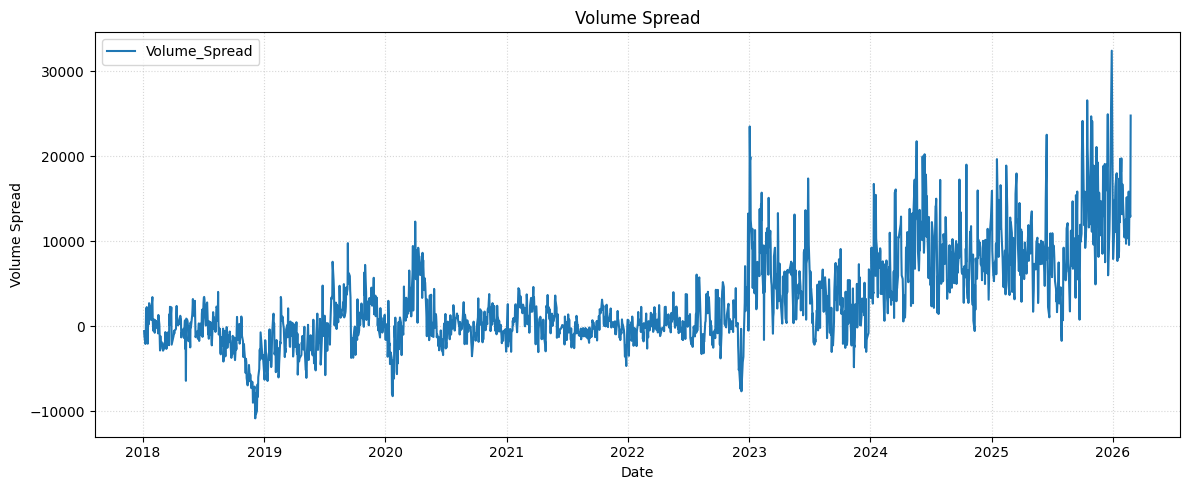

In [68]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")

plt.title("Volume Spread")
plt.xlabel("Date")
plt.ylabel("Volume Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

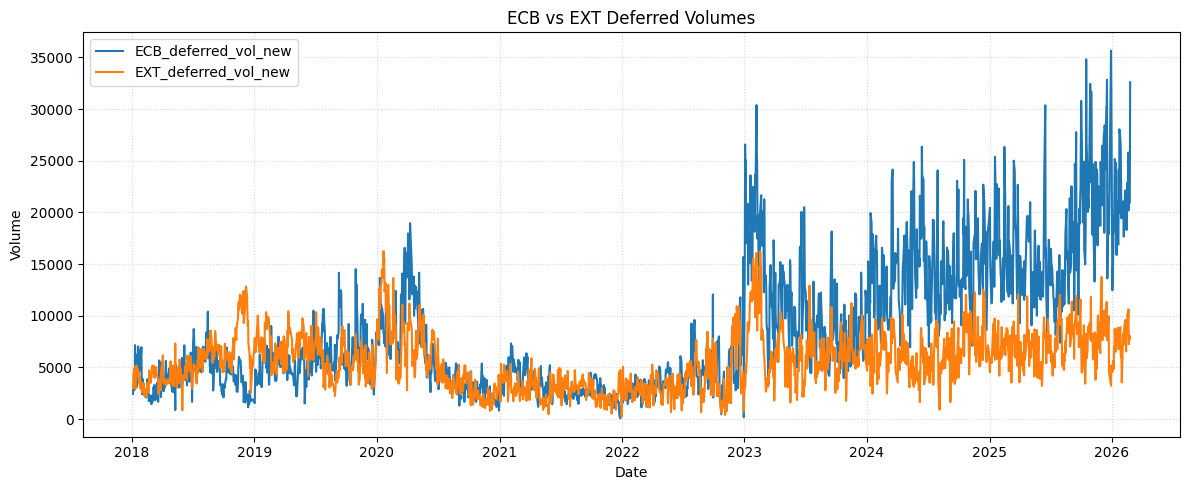

In [69]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["ECB_deferred_vol_new"], label="ECB_deferred_vol_new")
plt.plot(df["Date"], df["EXT_deferred_vol_new"], label="EXT_deferred_vol_new")

plt.title("ECB vs EXT Deferred Volumes")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

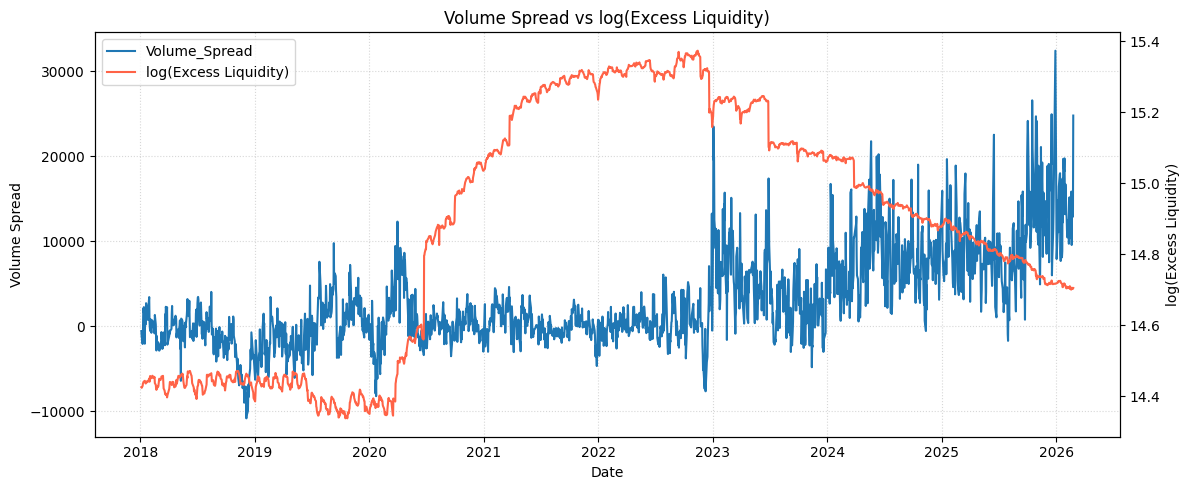

In [70]:
# -----------------------------
# 6) Volume Spread vs log(Excess Liquidity)
# -----------------------------
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("Volume Spread")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidityLn"], label="log(Excess Liquidity)", color = "tomato")
ax2.set_ylabel("log(Excess Liquidity)")

ax1.set_title("Volume Spread vs log(Excess Liquidity)")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

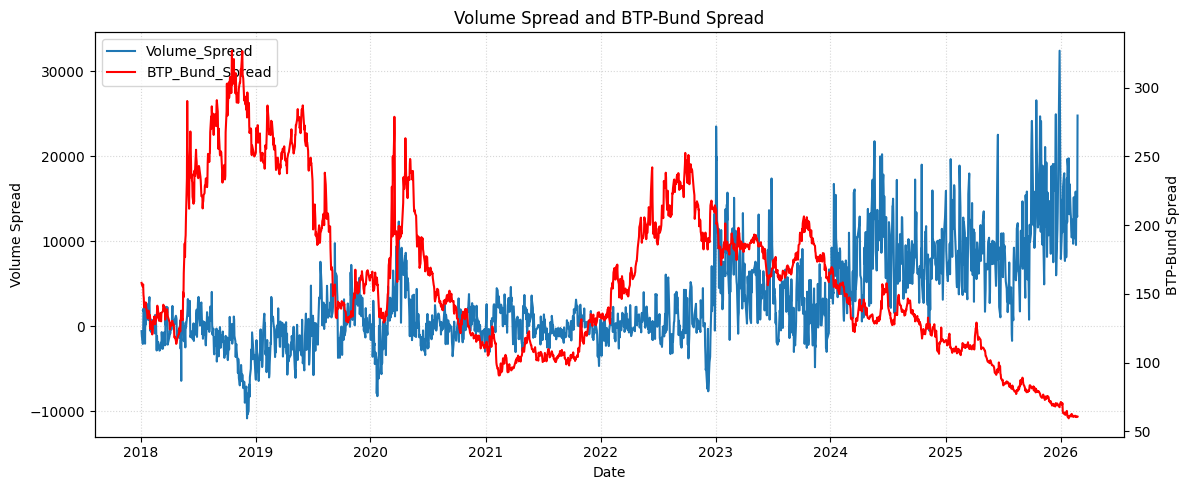

In [71]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("Volume Spread")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["BTP_Bund_Spread"], label="BTP_Bund_Spread", color="red")
ax2.set_ylabel("BTP-Bund Spread")

# Title + grid
ax1.set_title("Volume Spread and BTP-Bund Spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

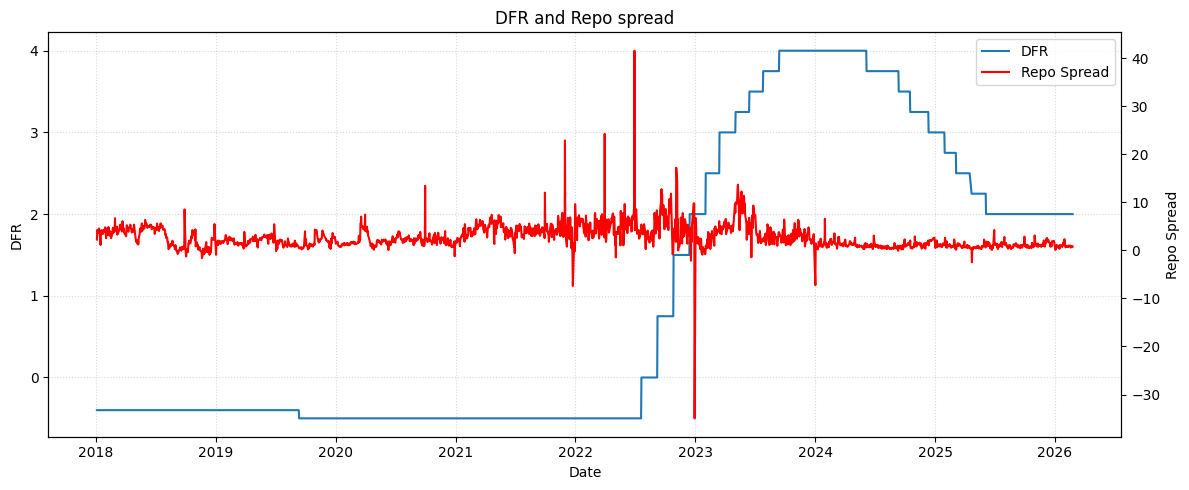

In [73]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["DFR"], label="DFR")
ax1.set_xlabel("Date")
ax1.set_ylabel("DFR")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["DeferredRateSpread"], label="Repo Spread", color="red")
ax2.set_ylabel("Repo Spread")

# Title + grid
ax1.set_title("DFR and Repo spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

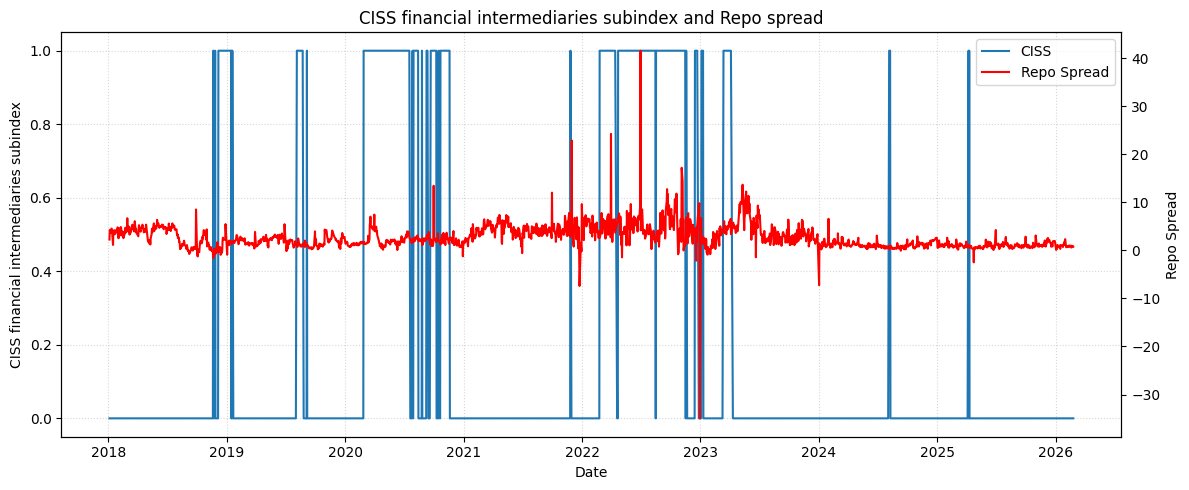

In [74]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["Stress_State"], label="CISS")
ax1.set_xlabel("Date")
ax1.set_ylabel("CISS financial intermediaries subindex")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["DeferredRateSpread"], label="Repo Spread", color="red")
ax2.set_ylabel("Repo Spread")

# Title + grid
ax1.set_title("CISS financial intermediaries subindex and Repo spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

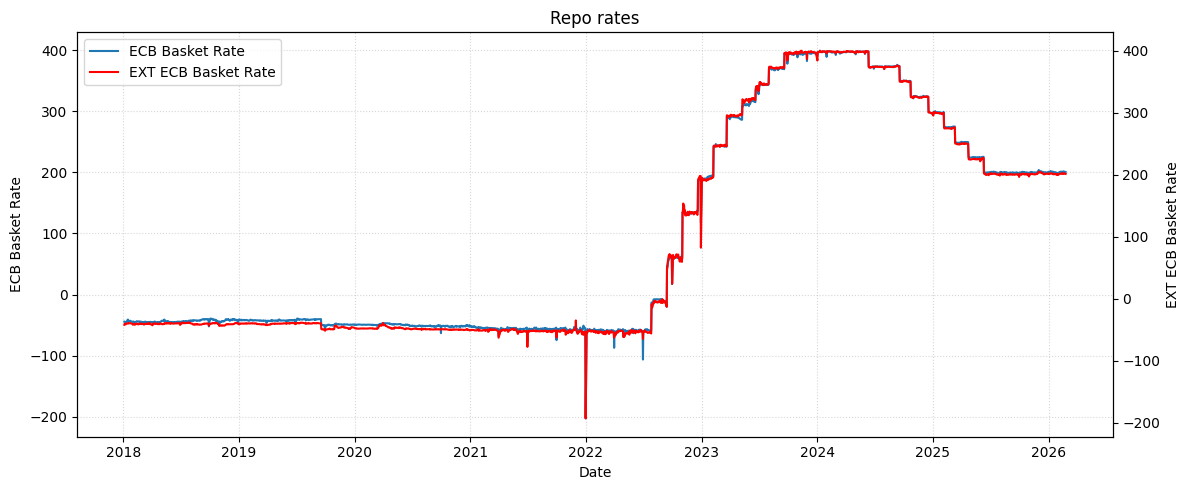

In [78]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["ECB_deferred_rate_new"], label="ECB Basket Rate")
ax1.set_xlabel("Date")
ax1.set_ylabel("ECB Basket Rate")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["EXT_deferred_rate_new"], label="EXT ECB Basket Rate", color="red")
ax2.set_ylabel("EXT ECB Basket Rate")

# Title + grid
ax1.set_title("Repo rates")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

# DATAFRAME STRUCTURE

In [244]:
df2 = df[[
    "Date",
    "ExcessLiquidity",
    "ExcessLiquidityLn",
    "BTP_Bund_Spread",
    "DeferredRateSpread",
    "ECB_deferred_vol_new",
    "EXT_deferred_vol_new",
    "Liquidity_ratio",
    "CISS",
    "DFR",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new", "DeferredVol", "DeferredRate"
    #"Stress_State"
]].dropna().copy()

print(df2.head())

        Date  ExcessLiquidity  ExcessLiquidityLn  BTP_Bund_Spread  \
2 2018-01-04          1841187          14.425921            158.0   
3 2018-01-05          1838165          14.424278            156.7   
4 2018-01-08          1847943          14.429584            155.3   
5 2018-01-09          1860708          14.436468            156.9   
6 2018-01-10          1865410          14.438991            149.5   

   DeferredRateSpread  ECB_deferred_vol_new  EXT_deferred_vol_new  \
2            2.266810                2449.0                3030.0   
3            4.273111                3029.0                4228.0   
4            3.696127                2810.0                4900.0   
5            3.962749                2957.0                3781.0   
6            4.554430                7164.0                5104.0   

   Liquidity_ratio    CISS   DFR  ECB_deferred_rate_new  \
2        -0.212883  0.0295 -40.0             -44.366149   
3        -0.333497  0.0251 -40.0             -44.594

In [245]:
df2['Log_DeferredRateSpread'] = np.log1p(df2['DeferredRateSpread'])
df2['Log_BTP_Bund_Spread'] = np.log1p(df2['BTP_Bund_Spread'])
df2['Lagged_Log_Spread'] = df2['Log_DeferredRateSpread'].shift(1)
df2['Delta_Liquidity'] = df2['ExcessLiquidityLn'].diff()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [246]:
# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['DeferredRateSpread'].quantile(0.05)
upper_cutoff = df2['DeferredRateSpread'].quantile(0.95)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['DeferredRateSpread'] > lower_cutoff) & 
               (df2['DeferredRateSpread'] < upper_cutoff)].copy()

In [247]:
df3.head()

,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,CISS,DFR,ECB_deferred_rate_new,EXT_deferred_rate_new,DeferredVol,DeferredRate,Log_DeferredRateSpread,Log_BTP_Bund_Spread,Lagged_Log_Spread,Delta_Liquidity
2,2018-01-04,1841187,14.425921,158.0,2.266810,2449.0,3030.0,-0.212883,0.0295,-40.0,-44.366149,-42.099340,5479,-43.2,1.183814,5.068904,NaN,NaN
3,2018-01-05,1838165,14.424278,156.7,4.273111,3029.0,4228.0,-0.333497,0.0251,-40.0,-44.594090,-40.320979,7257,-41.4,1.662621,5.060694,1.183814,-0.001643
4,2018-01-08,1847943,14.429584,155.3,3.696127,2810.0,4900.0,-0.556051,0.0246,-40.0,-44.870107,-41.173980,7710,-43.2,1.546738,5.051777,1.662621,0.005305
5,2018-01-09,1860708,14.436468,156.9,3.962749,2957.0,3781.0,-0.245813,0.0239,-40.0,-45.231011,-41.268262,6738,-43.4,1.601960,5.061962,1.546738,0.006884
6,2018-01-10,1865410,14.438991,149.5,4.554430,7164.0,5104.0,0.339044,0.0281,-40.0,-45.088442,-40.534013,12268,-42.6,1.714596,5.013963,1.601960,0.002524


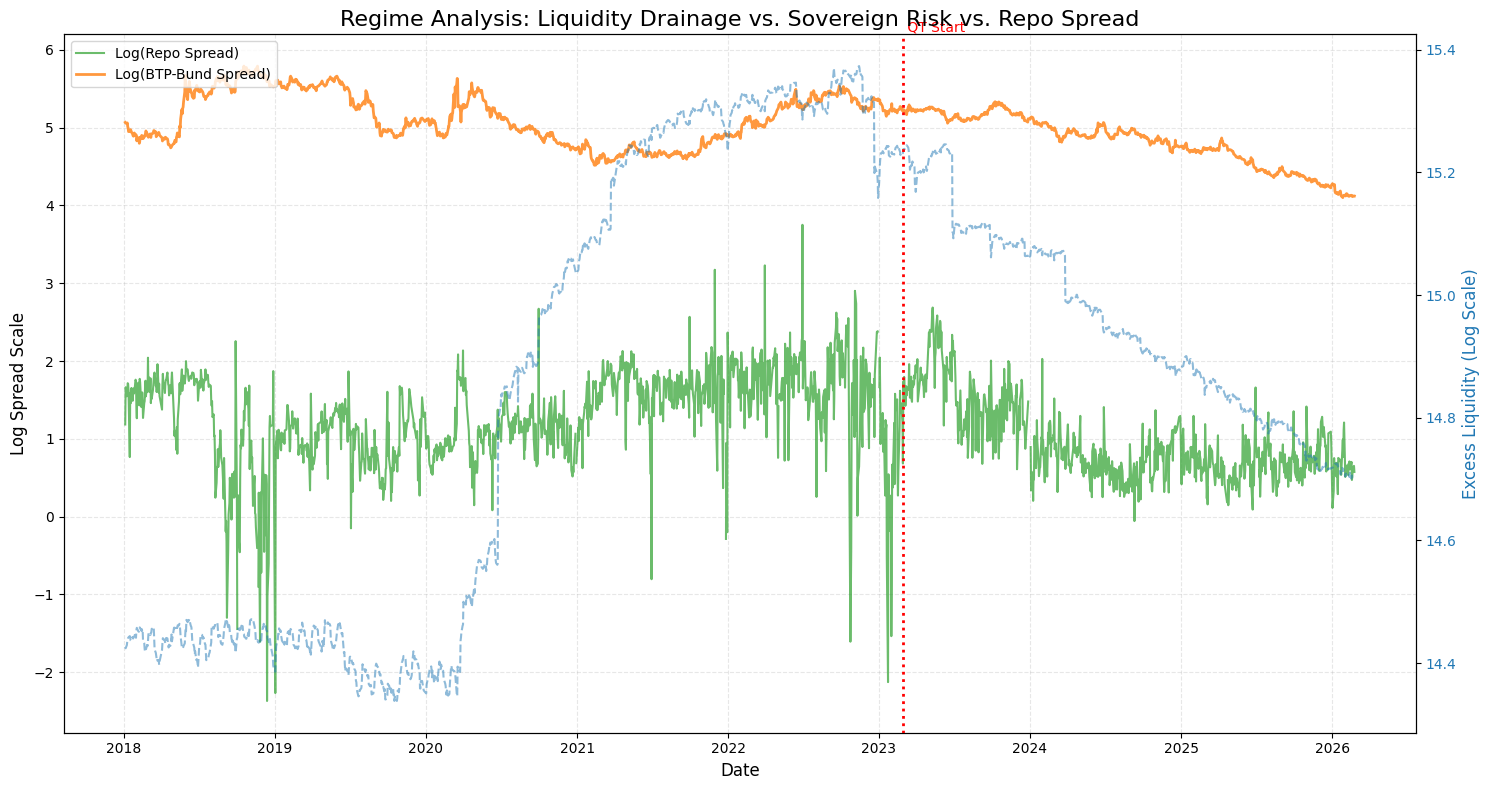

In [118]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Setup the figure
fig, ax1 = plt.subplots(figsize=(15, 8))

# 2. Plot the Spreads on the Primary Y-Axis (Left)
# These share a similar log-scale (roughly 1.0 to 5.5)
ax1.plot(df2['Date'], df2['Log_DeferredRateSpread'], 
         label='Log(Repo Spread)', color='#2ca02c', alpha=0.7, linewidth=1.5)
ax1.plot(df2['Date'], df2['Log_BTP_Bund_Spread'], 
         label='Log(BTP-Bund Spread)', color='#ff7f0e', alpha=0.8, linewidth=2)

ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Log Spread Scale', fontsize=12)
ax1.legend(loc='upper left')
ax1.grid(True, which='both', linestyle='--', alpha=0.3)

# 3. Plot Excess Liquidity on the Secondary Y-Axis (Right)
# This is in the 14.3 - 15.4 range (The "Elephant" scale)
ax2 = ax1.twinx()
ax2.plot(df2['Date'], df2['ExcessLiquidityLn'], 
         label='Excess Liquidity (Ln)', color='#1f77b4', linestyle='--', alpha=0.5)

ax2.set_ylabel('Excess Liquidity (Log Scale)', color='#1f77b4', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#1f77b4')

# 4. Annotate the QT Structural Break (March 1, 2023)
qt_start = pd.to_datetime('2023-03-01')
plt.axvline(qt_start, color='red', linestyle=':', linewidth=2, label='QT Start')
plt.text(qt_start, ax2.get_ylim()[1], ' QT Start', color='red', verticalalignment='bottom')

# 5. Final touches
plt.title('Regime Analysis: Liquidity Drainage vs. Sovereign Risk vs. Repo Spread', fontsize=16)
fig.tight_layout()
plt.show()

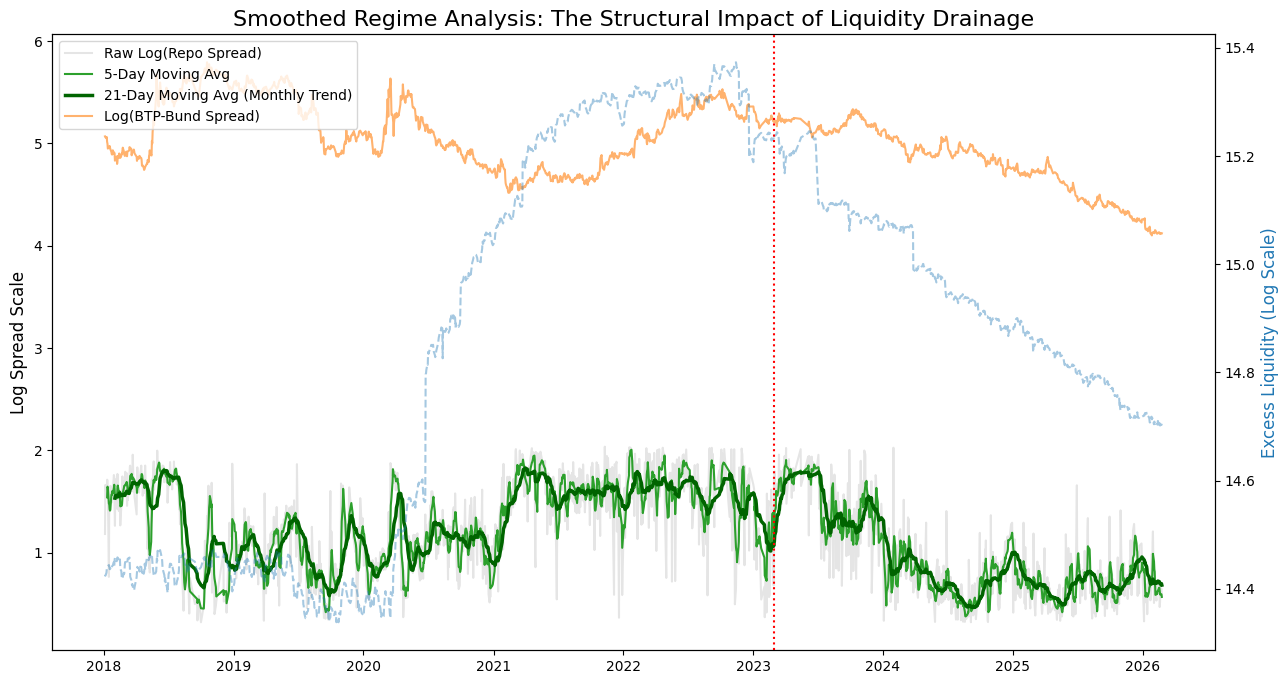

In [119]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate Moving Averages for the Repo Spread
# 5-day is good for "plumbing" noise; 21-day is the standard "trading month" trend
df_clean['Repo_MA_5'] = df_clean['Log_DeferredRateSpread'].rolling(window=5).mean()
df_clean['Repo_MA_21'] = df_clean['Log_DeferredRateSpread'].rolling(window=21).mean()

# 2. Setup the figure
fig, ax1 = plt.subplots(figsize=(15, 8))

# 3. Plot the Spreads (Left Axis)
# We keep the raw data in faint gray so we don't lose the "truth"
ax1.plot(df_clean['Date'], df_clean['Log_DeferredRateSpread'], 
         color='gray', alpha=0.2, label='Raw Log(Repo Spread)')

# Plot the Moving Averages
ax1.plot(df_clean['Date'], df_clean['Repo_MA_5'], 
         label='5-Day Moving Avg', color='#2ca02c', linewidth=1.5)
ax1.plot(df_clean['Date'], df_clean['Repo_MA_21'], 
         label='21-Day Moving Avg (Monthly Trend)', color='darkgreen', linewidth=2.5)

# Plot BTP Spread for comparison
ax1.plot(df_clean['Date'], df_clean['Log_BTP_Bund_Spread'], 
         label='Log(BTP-Bund Spread)', color='#ff7f0e', alpha=0.6, linewidth=1.5)

ax1.set_ylabel('Log Spread Scale', fontsize=12)
ax1.legend(loc='upper left')

# 4. Plot Excess Liquidity (Right Axis)
ax2 = ax1.twinx()
ax2.plot(df_clean['Date'], df_clean['ExcessLiquidityLn'], 
         label='Excess Liquidity (Ln)', color='#1f77b4', linestyle='--', alpha=0.4)
ax2.set_ylabel('Excess Liquidity (Log Scale)', color='#1f77b4', fontsize=12)

# 5. Annotations
plt.axvline(pd.to_datetime('2023-03-01'), color='red', linestyle=':', label='QT Start')
plt.title('Smoothed Regime Analysis: The Structural Impact of Liquidity Drainage', fontsize=16)

plt.show()

# Rolling Window Analaysis

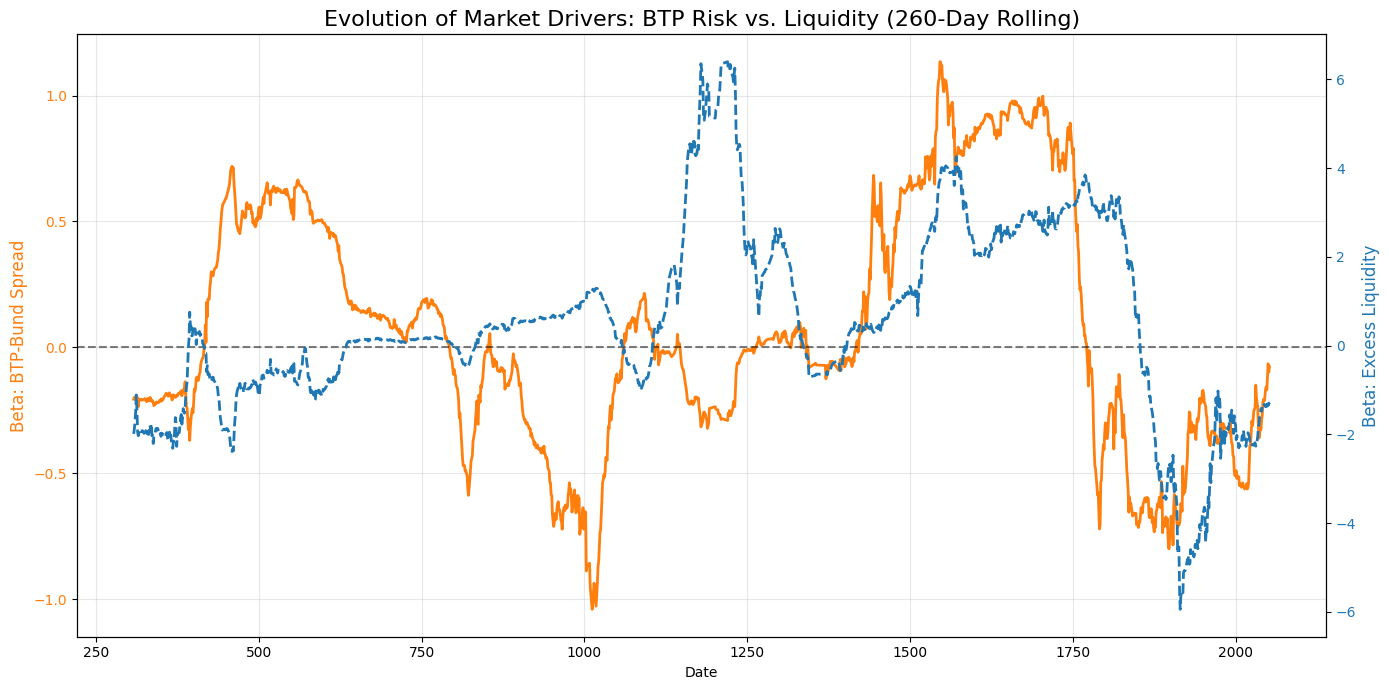

In [193]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Prepare the data (Ensure no NaNs from the shift)
df3['Lagged_Log_Spread'] = df3['Log_DeferredRateSpread'].shift(1)
df_rolling = df3.dropna(subset=['Lagged_Log_Spread', 'Delta_Liquidity', 'Log_BTP_Bund_Spread']).copy()

# 2. Define parameters
window = 260
betas_btp = []
betas_liq = []
dates = []

# 3. The Rolling Loop
for i in range(window, len(df_rolling)):
    window_data = df_rolling.iloc[i-window:i]
    
    y = window_data['Log_DeferredRateSpread']
    X = window_data[['Log_BTP_Bund_Spread', 'ExcessLiquidityLn', 'Lagged_Log_Spread','DFR']]
    X = sm.add_constant(X)
    
    model = sm.OLS(y, X).fit()
    
    betas_btp.append(model.params['Log_BTP_Bund_Spread'])
    betas_liq.append(model.params['ExcessLiquidityLn'])
    dates.append(df_rolling.index[i])

# 4. Plotting
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot BTP Beta on the Left Axis
color1 = 'tab:orange'
ax1.set_xlabel('Date')
ax1.set_ylabel('Beta: BTP-Bund Spread', color=color1, fontsize=12)
ax1.plot(dates, betas_btp, color=color1, linewidth=2, label='BTP-Bund Beta')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.axhline(0, color='black', linestyle='--', alpha=0.5)

# Create a second axis for Liquidity Beta
ax2 = ax1.twinx() 
color2 = 'tab:blue'
ax2.set_ylabel('Beta: Excess Liquidity', color=color2, fontsize=12)
ax2.plot(dates, betas_liq, color=color2, linewidth=2, label='Liquidity Beta', linestyle='--')
ax2.tick_params(axis='y', labelcolor=color2)

# Formatting
plt.title(f'Evolution of Market Drivers: BTP Risk vs. Liquidity ({window}-Day Rolling)', fontsize=16)
ax1.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

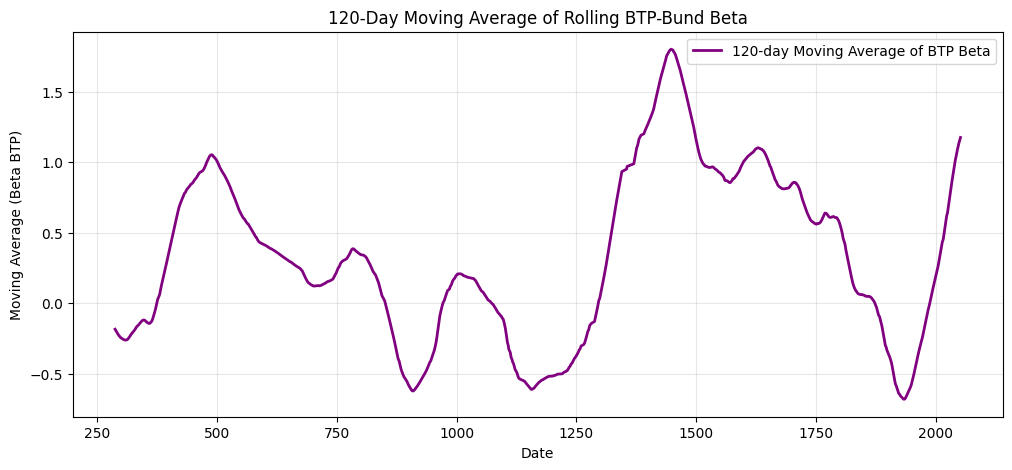

In [190]:
window = 120

# Compute the moving average
ma_btp = moving_average(betas_btp, window)

# Align dates correctly
ma_dates = dates[window - 1:]

# Plot
plt.figure(figsize=(12, 5))
plt.plot(ma_dates, ma_btp, label=f'{window}-day Moving Average of BTP Beta',
         color='purple', linewidth=2)
plt.xlabel("Date")
plt.ylabel("Moving Average (Beta BTP)")
plt.title(f"{window}-Day Moving Average of Rolling BTP-Bund Beta")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


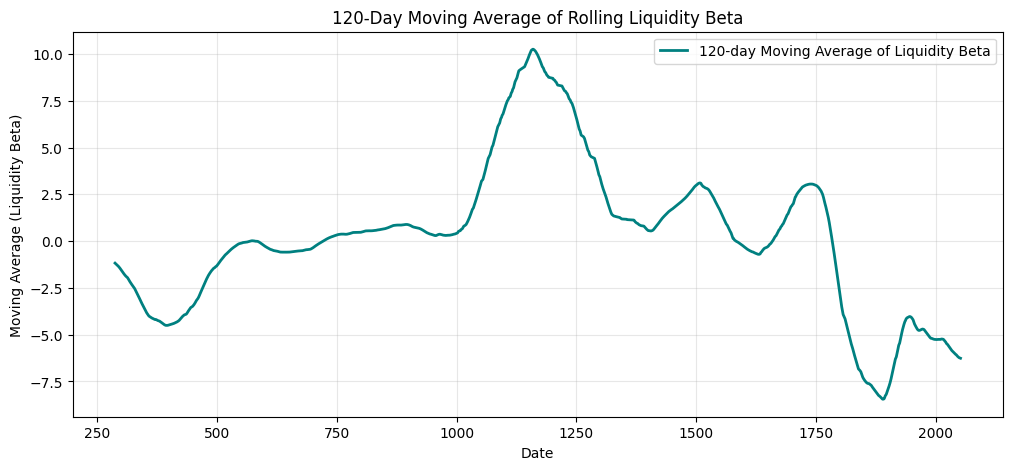

In [191]:
window = 120

# Compute the moving average for liquidity beta
ma_liq = moving_average(betas_liq, window)

# Align dates correctly
ma_dates_liq = dates[window - 1:]

# Plot
plt.figure(figsize=(12, 5))
plt.plot(ma_dates_liq, ma_liq, 
         label=f'{window}-day Moving Average of Liquidity Beta',
         color='teal', linewidth=2)

plt.xlabel("Date")
plt.ylabel("Moving Average (Liquidity Beta)")
plt.title(f"{window}-Day Moving Average of Rolling Liquidity Beta")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


C:\Users\shree\AppData\Local\Temp\ipykernel_31308\599924389.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df['Date'].iloc[::120], rotation=45)


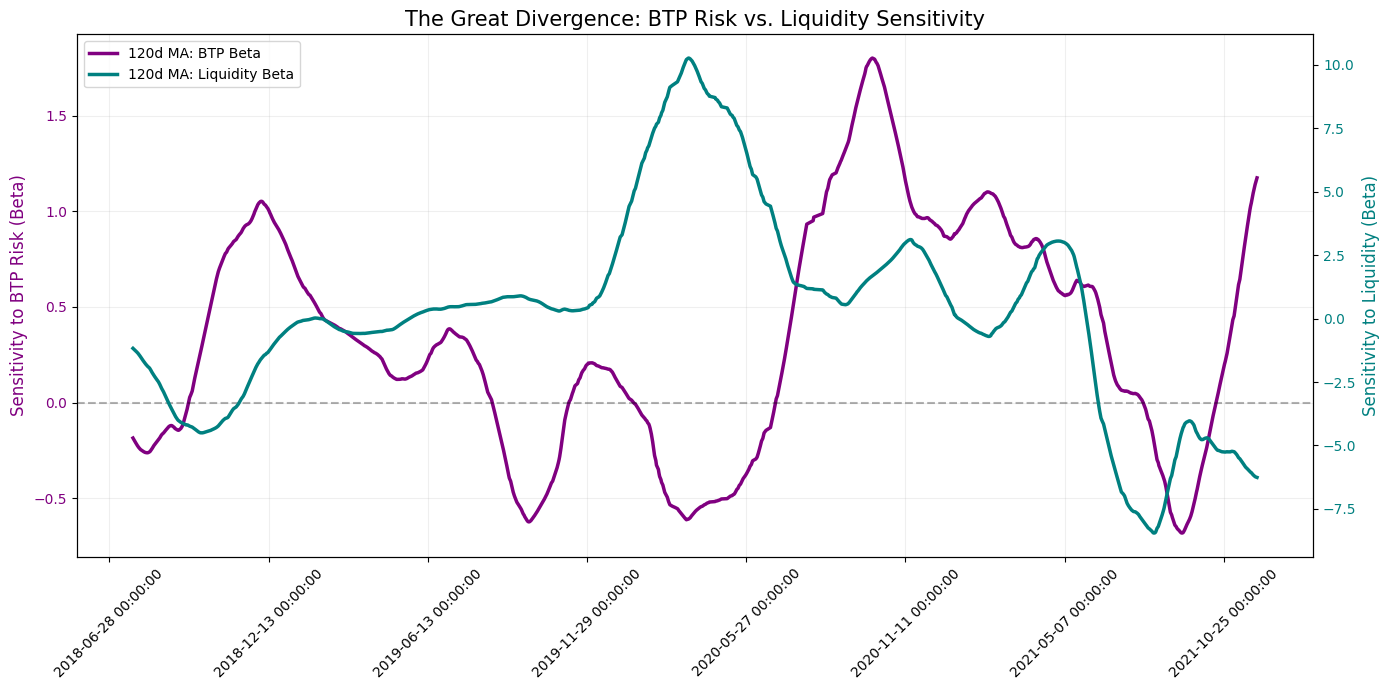

In [192]:
import matplotlib.pyplot as plt

# 1. Setup the figure and primary axis
fig, ax1 = plt.subplots(figsize=(14, 7))

# 2. Plot BTP Beta (Purple)
ax1.plot(ma_dates, ma_btp, color='purple', linewidth=2.5, label='120d MA: BTP Beta')
ax1.set_xticklabels(df['Date'].iloc[::120], rotation=45)
ax1.set_ylabel('Sensitivity to BTP Risk (Beta)', color='purple', fontsize=12)
ax1.tick_params(axis='y', labelcolor='purple')
ax1.axhline(0, color='black', linestyle='--', alpha=0.3) # Zero line for reference

# 3. Setup the secondary axis for Liquidity Beta
ax2 = ax1.twinx()
ax2.plot(ma_dates_liq, ma_liq, color='teal', linewidth=2.5, linestyle='-', label='120d MA: Liquidity Beta')
ax2.set_ylabel('Sensitivity to Liquidity (Beta)', color='teal', fontsize=12)
ax2.tick_params(axis='y', labelcolor='teal')

# 4. Final Formatting
plt.title('The Great Divergence: BTP Risk vs. Liquidity Sensitivity', fontsize=15)
fig.tight_layout()
ax1.grid(True, alpha=0.2)

# Combine legends from both axes
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

plt.show()

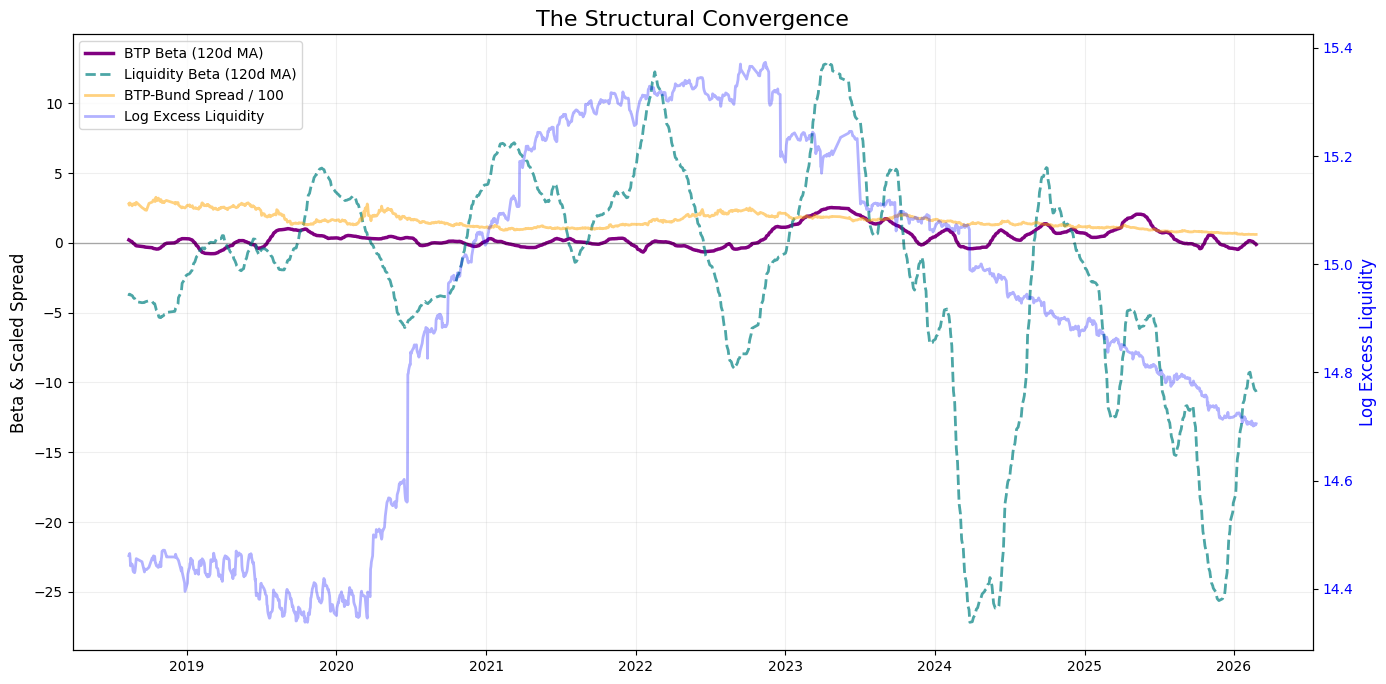

In [181]:
import matplotlib.pyplot as plt

# 1. Determine the shortest length among all your arrays
# This ensures we don't have a mismatch
min_len = min(len(ma_btp), len(ma_liq), len(df3))

# 2. Slice everything to match the length of the moving averages (from the end)
# This aligns the most recent data points correctly
dates_final = df3['Date'].iloc[-min_len:]
btp_spread_final = (df3['BTP_Bund_Spread'].iloc[-min_len:]) / 100
liquidity_final = df3['ExcessLiquidityLn'].iloc[-min_len:]

# Ensure the betas are also sliced to min_len if they are longer
ma_btp_final = ma_btp[-min_len:]
ma_liq_final = ma_liq[-min_len:]

# 3. Setup the figure
fig, ax1 = plt.subplots(figsize=(16, 8))

# 4. Plot the Sensitivities (Left Axis)
ax1.plot(dates_final, ma_btp_final, color='purple', linewidth=2.5, label='BTP Beta (120d MA)')
ax1.plot(dates_final, ma_liq_final, color='teal', linewidth=2, linestyle='--', alpha=0.7, label='Liquidity Beta (120d MA)')
ax1.plot(dates_final, btp_spread_final, color='orange', linewidth=2, alpha=0.5, label='BTP-Bund Spread / 100')

ax1.set_ylabel('Beta & Scaled Spread', fontsize=12)
ax1.axhline(0, color='black', linewidth=1, alpha=0.3)

# 5. Plot Excess Liquidity (Right Axis)
ax2 = ax1.twinx()
ax2.plot(dates_final, liquidity_final, color='blue', linewidth=2, alpha=0.3, label='Log Excess Liquidity')
ax2.set_ylabel('Log Excess Liquidity', color='blue', fontsize=12)
ax2.tick_params(axis='y', labelcolor='blue')

# 6. Formatting
plt.title('The Structural Convergence', fontsize=16)
ax1.grid(True, alpha=0.2)

# Legend handling
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

# Data Modelling

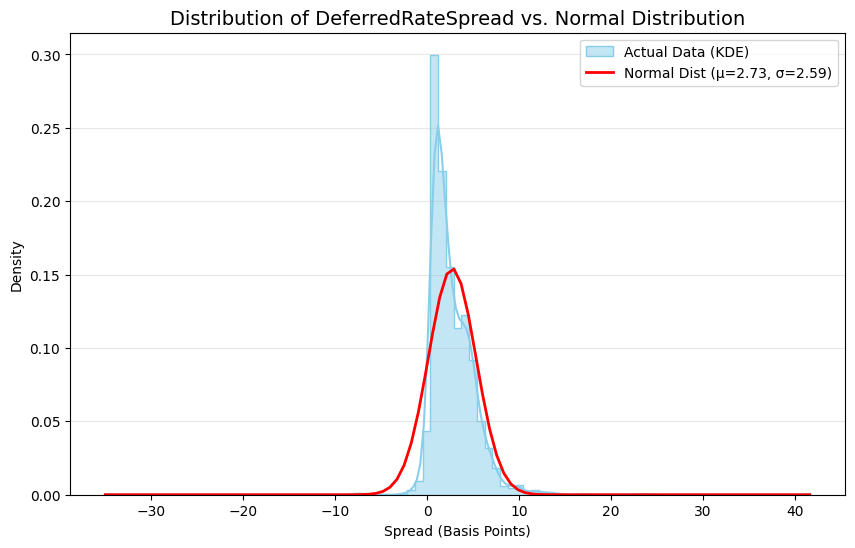

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['DeferredRateSpread'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['DeferredRateSpread'].mean(), df2['DeferredRateSpread'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['DeferredRateSpread'].min(), df2['DeferredRateSpread'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of DeferredRateSpread vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


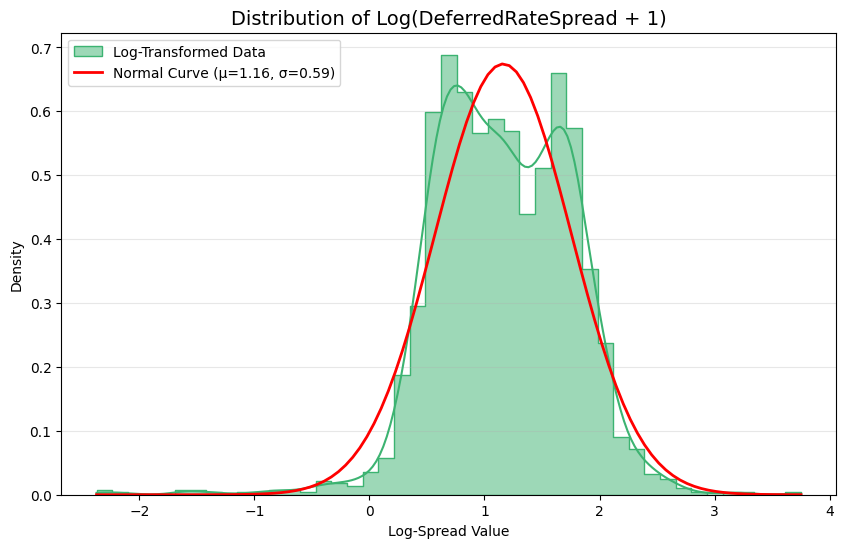

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Apply the Log-Plus-One transformation
# We add 1 to ensure all values are positive before logging
df2['Log_DeferredRateSpread'] = np.log1p(df2['DeferredRateSpread'])

# 2. Setup the figure
plt.figure(figsize=(10, 6))

# 3. Plot the Log-transformed distribution
sns.histplot(df2['Log_DeferredRateSpread'], kde=True, element="step", 
             color="mediumseagreen", stat="density", label='Log-Transformed Data')

# 4. Overlay the Normal Distribution for comparison
mu_log, std_log = df2['Log_DeferredRateSpread'].mean(), df2['Log_DeferredRateSpread'].std()
x = np.linspace(df2['Log_DeferredRateSpread'].min(), df2['Log_DeferredRateSpread'].max(), 100)
p = norm.pdf(x, mu_log, std_log)

plt.plot(x, p, 'r', linewidth=2, label=f'Normal Curve (μ={mu_log:.2f}, σ={std_log:.2f})')

# 5. Formatting
plt.title('Distribution of Log(DeferredRateSpread + 1)', fontsize=14)
plt.xlabel('Log-Spread Value')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

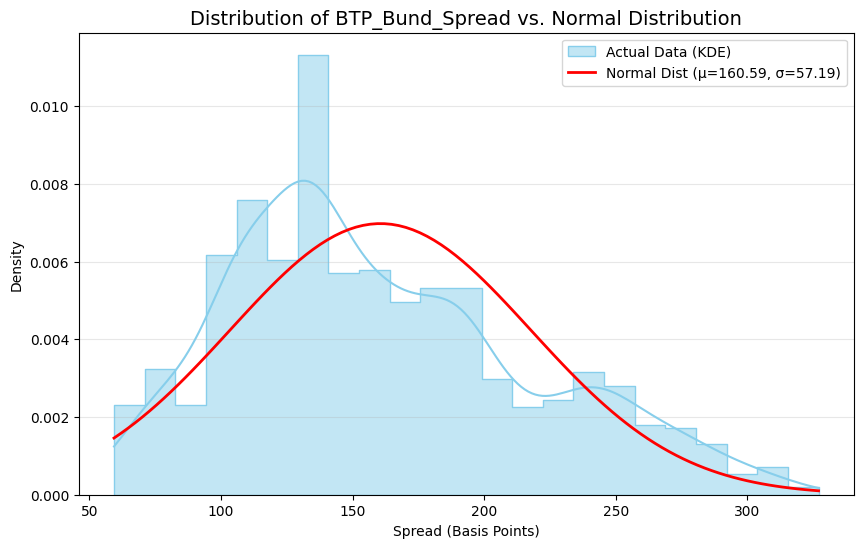

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['BTP_Bund_Spread'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['BTP_Bund_Spread'].mean(), df2['BTP_Bund_Spread'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['BTP_Bund_Spread'].min(), df2['BTP_Bund_Spread'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of BTP_Bund_Spread vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

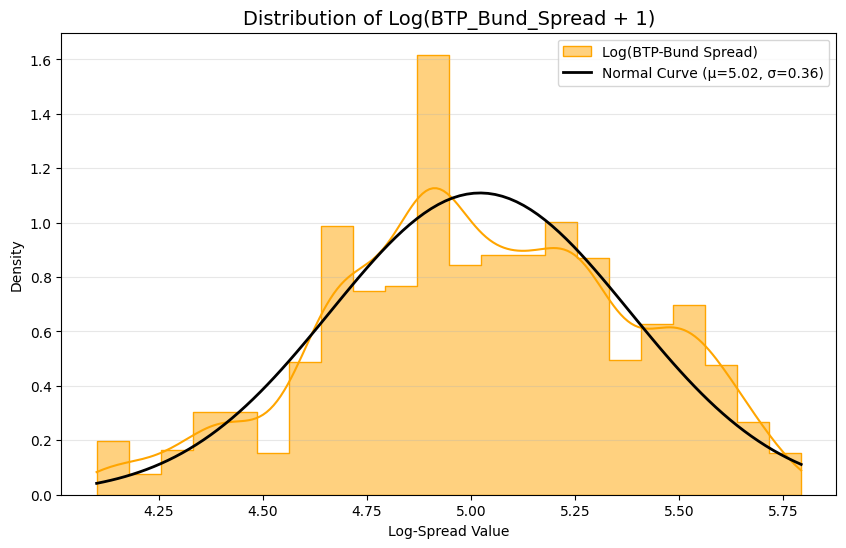

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Apply Log transformation to BTP_Bund_Spread
# We use log1p in case the spread ever touches zero (unlikely but safe practice)
df2['Log_BTP_Bund_Spread'] = np.log1p(df2['BTP_Bund_Spread'])

# 2. Setup the figure
plt.figure(figsize=(10, 6))

# 3. Plot the Log-transformed distribution
sns.histplot(df2['Log_BTP_Bund_Spread'], kde=True, element="step", 
             color="orange", stat="density", label='Log(BTP-Bund Spread)')

# 4. Overlay the Normal Distribution curve
mu_btp, std_btp = df2['Log_BTP_Bund_Spread'].mean(), df2['Log_BTP_Bund_Spread'].std()
x = np.linspace(df2['Log_BTP_Bund_Spread'].min(), df2['Log_BTP_Bund_Spread'].max(), 100)
p = norm.pdf(x, mu_btp, std_btp)

plt.plot(x, p, 'k', linewidth=2, label=f'Normal Curve (μ={mu_btp:.2f}, σ={std_btp:.2f})')

# 5. Formatting
plt.title('Distribution of Log(BTP_Bund_Spread + 1)', fontsize=14)
plt.xlabel('Log-Spread Value')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

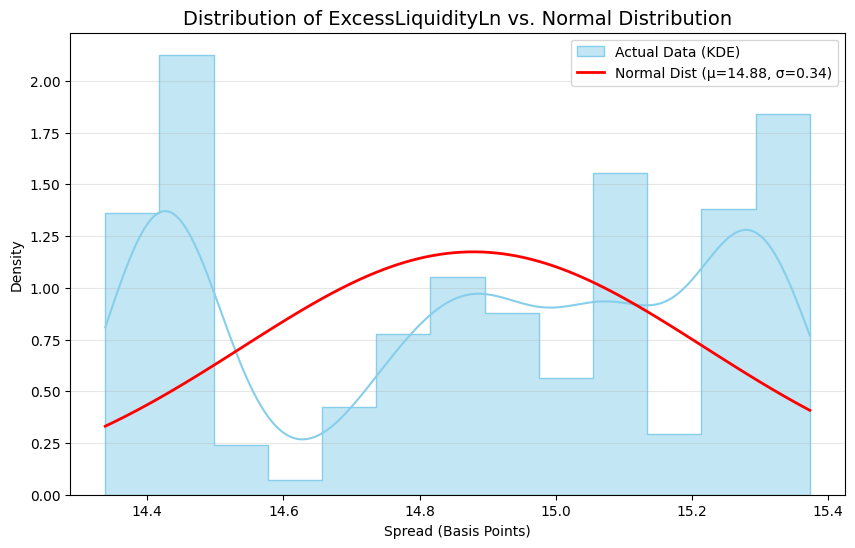

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['ExcessLiquidityLn'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['ExcessLiquidityLn'].mean(), df2['ExcessLiquidityLn'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['ExcessLiquidityLn'].min(), df2['ExcessLiquidityLn'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of ExcessLiquidityLn vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

# Regime Shift Coding

In [252]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

df_QE= df3[(df3['Date'] < "2022-06-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Log_DeferredRateSpread ~ '
    'Lagged_Log_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    'ExcessLiquidityLn + '  # The Stock Level
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df_QE).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                              OLS Regression Results                              
Dep. Variable:     Log_DeferredRateSpread   R-squared:                       0.607
Model:                                OLS   Adj. R-squared:                  0.605
Method:                     Least Squares   F-statistic:                     138.1
Date:                    Tue, 07 Apr 2026   Prob (F-statistic):          1.14e-111
Time:                            20:27:48   Log-Likelihood:                -74.035
No. Observations:                    1018   AIC:                             160.1
Df Residuals:                        1012   BIC:                             189.6
Df Model:                               5                                         
Covariance Type:                      HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

In [254]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

df_QT= df3[(df3['Date'] >= "2022-06-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Log_DeferredRateSpread ~ '
    'Lagged_Log_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    'ExcessLiquidityLn + '  # The Stock Level
    'DeferredRate'
)

model_shock = smf.ols(formula=formula_shock, data=df_QT).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                              OLS Regression Results                              
Dep. Variable:     Log_DeferredRateSpread   R-squared:                       0.660
Model:                                OLS   Adj. R-squared:                  0.657
Method:                     Least Squares   F-statistic:                     199.0
Date:                    Tue, 07 Apr 2026   Prob (F-statistic):          2.23e-138
Time:                            20:28:44   Log-Likelihood:                -86.255
No. Observations:                     818   AIC:                             184.5
Df Residuals:                         812   BIC:                             212.8
Df Model:                               5                                         
Covariance Type:                      HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

# One Model Fits All

In [260]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2


# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Log_DeferredRateSpread ~ '
    'Lagged_Log_Spread + '
    'Log_BTP_Bund_Spread + '
    'ExcessLiquidityLn + '  # The Stock Level
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df3).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                              OLS Regression Results                              
Dep. Variable:     Log_DeferredRateSpread   R-squared:                       0.646
Model:                                OLS   Adj. R-squared:                  0.646
Method:                     Least Squares   F-statistic:                     508.1
Date:                    Tue, 07 Apr 2026   Prob (F-statistic):          6.54e-295
Time:                            20:35:27   Log-Likelihood:                -225.55
No. Observations:                    1836   AIC:                             461.1
Df Residuals:                        1831   BIC:                             488.7
Df Model:                               4                                         
Covariance Type:                      HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

# Volume Model

In [233]:
df3.head()

,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,CISS,DFR,ECB_deferred_rate_new,EXT_deferred_rate_new,DeferredVol,DeferredRate,Log_DeferredRateSpread,Log_BTP_Bund_Spread,Lagged_Log_Spread,Delta_Liquidity
2,2018-01-04,1841187,14.425921,158.0,2.266810,2449.0,3030.0,0.973444,0.0295,-40.0,-44.366149,-42.099340,5479,-43.2,1.183814,5.068904,NaN,NaN
3,2018-01-05,1838165,14.424278,156.7,4.273111,3029.0,4228.0,0.960058,0.0251,-40.0,-44.594090,-40.320979,7257,-41.4,1.662621,5.060694,1.183814,-0.001643
4,2018-01-08,1847943,14.429584,155.3,3.696127,2810.0,4900.0,0.934559,0.0246,-40.0,-44.870107,-41.173980,7710,-43.2,1.546738,5.051777,1.662621,0.005305
5,2018-01-09,1860708,14.436468,156.9,3.962749,2957.0,3781.0,0.970160,0.0239,-40.0,-45.231011,-41.268262,6738,-43.4,1.601960,5.061962,1.546738,0.006884
6,2018-01-10,1865410,14.438991,149.5,4.554430,7164.0,5104.0,1.039711,0.0281,-40.0,-45.088442,-40.534013,12268,-42.6,1.714596,5.013963,1.601960,0.002524
